In [31]:
# ============================================================
# 1. Setup
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [40]:
# ============================================================
# 2. Daten laden
# ============================================================

df_raw = pd.read_excel(
    "C:\\Users\\janis\\OneDrive - FHNW\\P-pro2Db_Ausfälle-in-Schlammtrockungsanlage_M365 - STRAG AG\\Data\\Prozess\\FHNW_PLS_Info_2026-03.xlsx"
)

df_raw.head()

,Datum,PARA-2024,LI-213,H-001,GM-002,GS-100,TM-101,H-002,H-005A,H-005B,P-002C,P-002B
0,NaT,Anzeige Bänderstopp,Niveau Nass-Schlamm,Feuchtschlamm Trogkettenförderer,Feuchtschlamm Dosierer,Stellung Matrize Betrieb,Trockner Antrieb Band 1,Austragsschnecke Trockner,Austragsschneckenwelle 1 Granulat,Austragsschneckenwelle 2 Granulat,Umwälzpumpe 2. Brüdenkreislauf,Umwälzpumpe 2 Rückkühlkreislauf
1,NaT,NaN,m,Hz,Hz,%,Hz,%,%,%,Hz,%
2,NaT,Mittel,Mittel,Mittel,Mittel,Mittel,Mittel,Mittel,Mittel,Mittel,Mittel,Mittel
3,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026-03-01,0,2.5,25,35.5,100,47,100,0,0,0,35


In [41]:
# ============================================================
# Parameter-Legende aus Metadaten erstellen
# ============================================================

parameter_legend = df_raw.iloc[0:3].T.reset_index()

parameter_legend.columns = ["Parameter", "Beschreibung", "Einheit", "Aggregation"]

parameter_legend

,Parameter,Beschreibung,Einheit,Aggregation
0,Datum,NaT,NaT,NaT
1,PARA-2024,Anzeige Bänderstopp,NaN,Mittel
2,LI-213,Niveau Nass-Schlamm,m,Mittel
3,H-001,Feuchtschlamm Trogkettenförderer,Hz,Mittel
4,GM-002,Feuchtschlamm Dosierer,Hz,Mittel
5,GS-100,Stellung Matrize Betrieb,%,Mittel
6,TM-101,Trockner Antrieb Band 1,Hz,Mittel
7,H-002,Austragsschnecke Trockner,%,Mittel
8,H-005A,Austragsschneckenwelle 1 Granulat,%,Mittel
9,H-005B,Austragsschneckenwelle 2 Granulat,%,Mittel


In [15]:
df = df_raw.iloc[4:].reset_index(drop=True)

df.head()

,Datum,PARA-2024,LI-213,H-001,GM-002,GS-100,TM-101,H-002,H-005A,H-005B,P-002C,P-002B
0,2026-03-01 00:00:00,0,2.5,25,35.5,100,47,100,0,0,0,35
1,2026-03-01 00:05:00,0,2.6,25,35.5,100,47,100,0,0,0,35
2,2026-03-01 00:10:00,0,2.4,25,35.4,100,47,100,0,0,0,35
3,2026-03-01 00:15:00,0,2.4,25,35.4,100,47,100,0,0,0,35
4,2026-03-01 00:20:00,0,2.4,25,35.3,100,47,100,0,0,0,35


In [10]:
# ============================================================
# 3. Erster Überblick
# ============================================================

print(f"Zeilen: {df.shape[0]}")
print(f"Spalten: {df.shape[1]}")

df.info()

Zeilen: 8915
Spalten: 12
<class 'pandas.DataFrame'>
RangeIndex: 8915 entries, 0 to 8914
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Datum      8915 non-null   datetime64[us]
 1   PARA-2024  8915 non-null   object        
 2   LI-213     8915 non-null   object        
 3   H-001      8915 non-null   object        
 4   GM-002     8915 non-null   object        
 5   GS-100     8915 non-null   object        
 6   TM-101     8915 non-null   object        
 7   H-002      8915 non-null   object        
 8   H-005A     8915 non-null   object        
 9   H-005B     8915 non-null   object        
 10  P-002C     8915 non-null   object        
 11  P-002B     8915 non-null   object        
dtypes: datetime64[us](1), object(11)
memory usage: 835.9+ KB


In [16]:
exclude_cols = ["Datum"]

df = df.copy()

for col in df.columns:
    if col in exclude_cols:
        continue

    converted = pd.to_numeric(df[col], errors="coerce")

    # Nur ersetzen, wenn die Spalte nach der Umwandlung nicht komplett leer wäre
    if converted.notna().sum() > 0:
        df[col] = converted

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8915 entries, 0 to 8914
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Datum      8915 non-null   datetime64[us]
 1   PARA-2024  8915 non-null   int64         
 2   LI-213     8915 non-null   float64       
 3   H-001      8915 non-null   float64       
 4   GM-002     8915 non-null   float64       
 5   GS-100     8915 non-null   int64         
 6   TM-101     8915 non-null   float64       
 7   H-002      8915 non-null   int64         
 8   H-005A     8915 non-null   int64         
 9   H-005B     8915 non-null   int64         
 10  P-002C     8915 non-null   float64       
 11  P-002B     8915 non-null   float64       
dtypes: datetime64[us](1), float64(6), int64(5)
memory usage: 835.9 KB


In [17]:
df.head()

,Datum,PARA-2024,LI-213,H-001,GM-002,GS-100,TM-101,H-002,H-005A,H-005B,P-002C,P-002B
0,2026-03-01 00:00:00,0,2.5,25.0,35.5,100,47.0,100,0,0,0.0,35.0
1,2026-03-01 00:05:00,0,2.6,25.0,35.5,100,47.0,100,0,0,0.0,35.0
2,2026-03-01 00:10:00,0,2.4,25.0,35.4,100,47.0,100,0,0,0.0,35.0
3,2026-03-01 00:15:00,0,2.4,25.0,35.4,100,47.0,100,0,0,0.0,35.0
4,2026-03-01 00:20:00,0,2.4,25.0,35.3,100,47.0,100,0,0,0.0,35.0


In [18]:
df.describe(include="all").T

,count,mean,min,25%,50%,75%,max,std
Datum,8915,2026-03-16 11:30:33.954010,2026-03-01 00:00:00,2026-03-08 17:42:30,2026-03-16 11:25:00,2026-03-24 05:07:30,2026-03-31 23:50:00,NaN
PARA-2024,8915.0,0.042961,0.0,0.0,0.0,0.0,6.0,0.261283
LI-213,8915.0,3.428491,0.5,2.7,3.8,4.4,5.6,1.252021
H-001,8915.0,21.494033,0.0,25.0,25.0,25.0,25.0,8.628333
GM-002,8915.0,39.014403,0.0,36.3,49.3,50.0,50.0,17.09111
GS-100,8915.0,99.568592,0.0,100.0,100.0,100.0,100.0,5.757893
TM-101,8915.0,40.787168,0.0,47.0,47.0,47.0,47.0,15.832231
H-002,8915.0,87.414358,0.0,100.0,100.0,100.0,100.0,33.088946
H-005A,8915.0,4.553449,0.0,0.0,0.0,0.0,100.0,20.012043
H-005B,8915.0,1.032754,0.0,0.0,0.0,0.0,100.0,9.564223


In [21]:
# ============================================================
# 5. Spaltentypen trennen
# ============================================================

num_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numerische Spalten:", num_cols)
print("Kategorische Spalten:", cat_cols)

Numerische Spalten: ['PARA-2024', 'LI-213', 'H-001', 'GM-002', 'GS-100', 'TM-101', 'H-002', 'H-005A', 'H-005B', 'P-002C', 'P-002B']
Kategorische Spalten: []


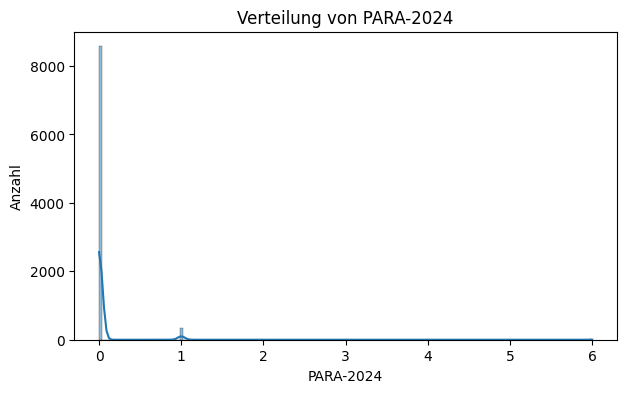

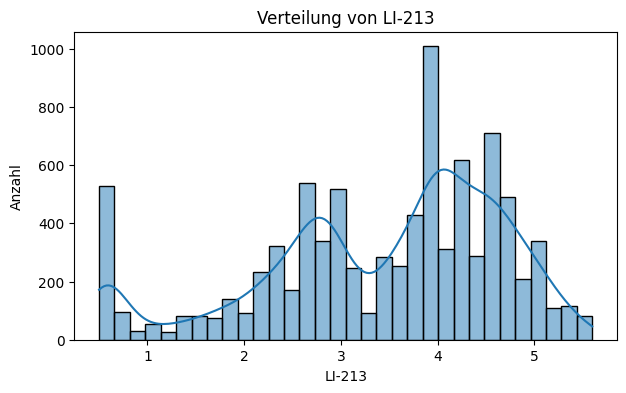

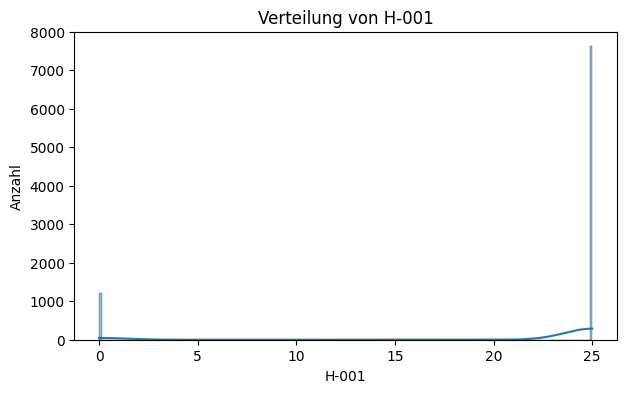

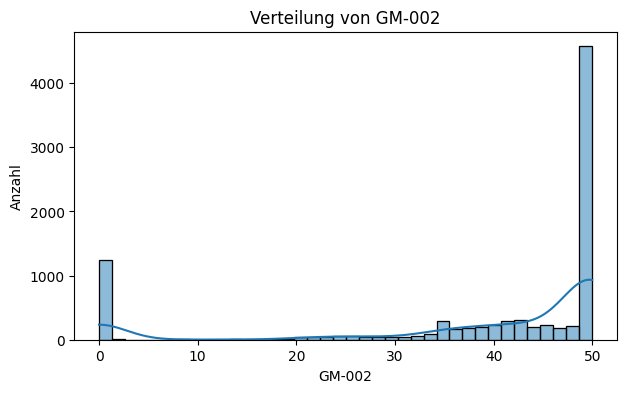

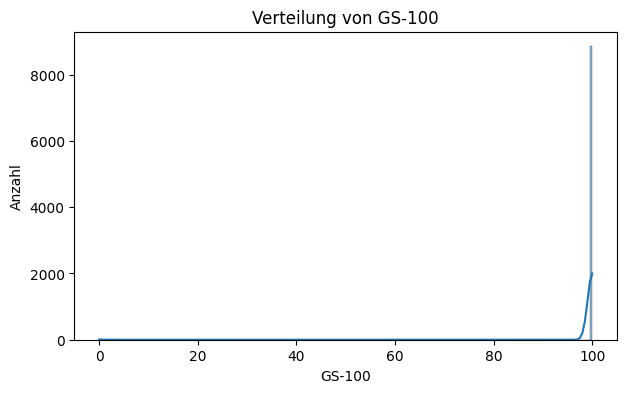

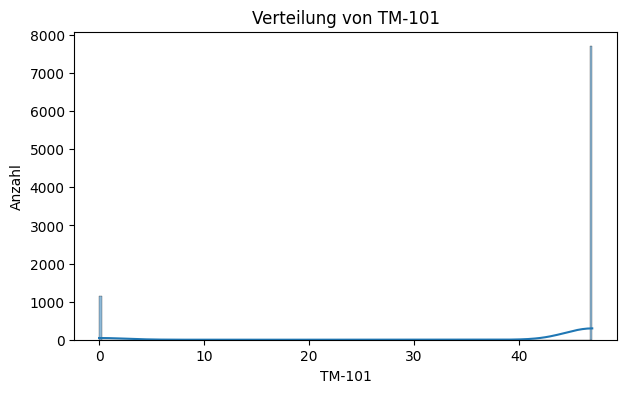

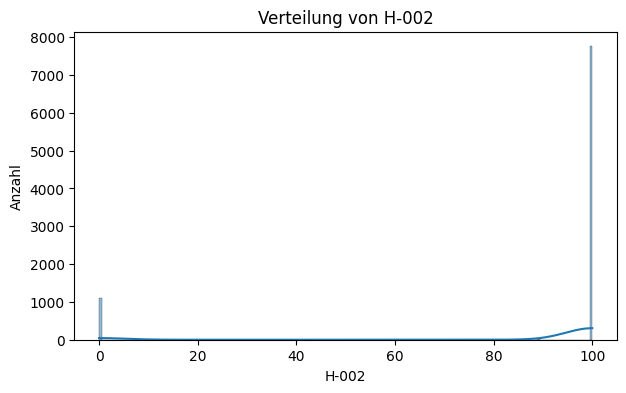

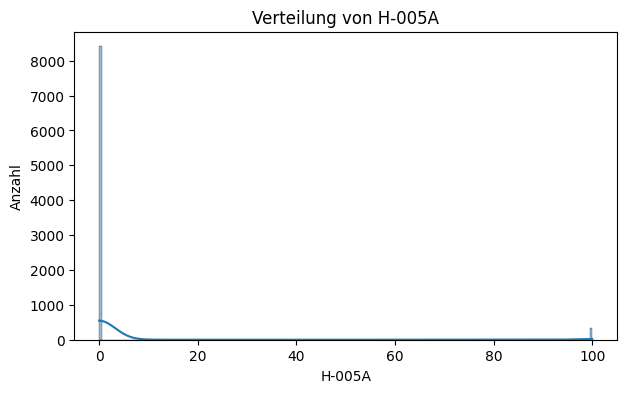

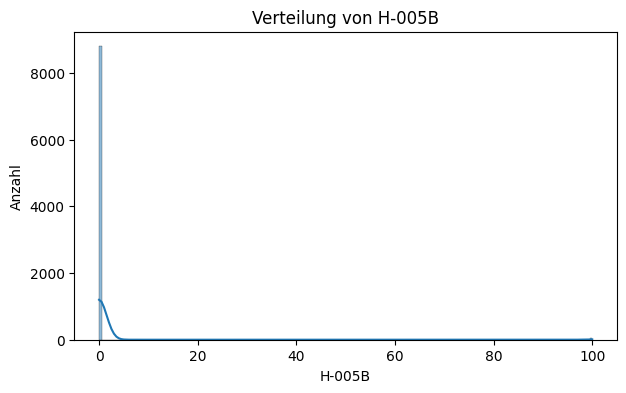

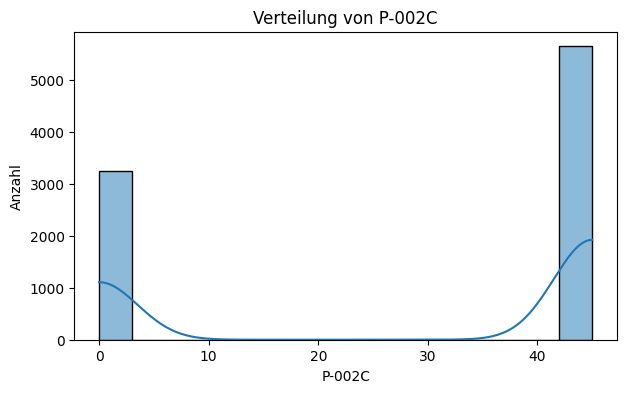

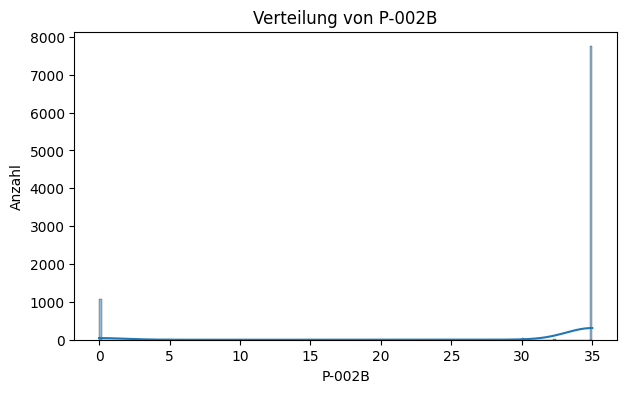

In [26]:
# ============================================================
# 6. Univariate Analyse: Numerische Variablen
# ============================================================

for col in num_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(f"Verteilung von {col}")
    plt.xlabel(col)
    plt.ylabel("Anzahl")
    plt.show()

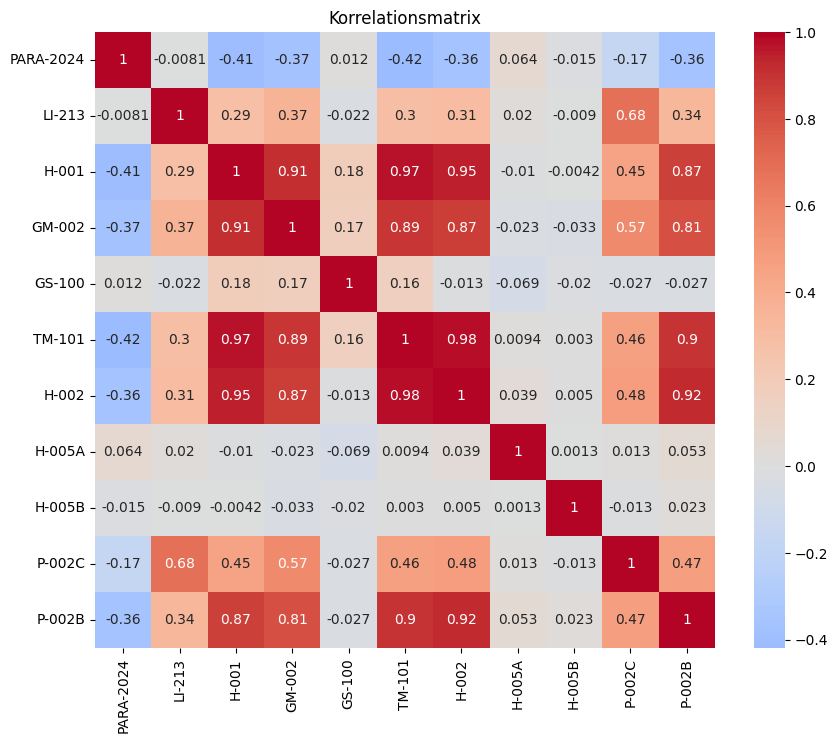

In [29]:
# ============================================================
# 8. Korrelationen
# ============================================================

corr = df[num_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.title("Korrelationsmatrix")
plt.show()

In [32]:
# ============================================================
# 8.1 Stärkste Korrelationen anzeigen
# ============================================================

corr_pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))  # doppelte Paare entfernen
    .stack()
    .reset_index()
)

corr_pairs.columns = ["feature_1", "feature_2", "correlation"]

corr_pairs["abs_correlation"] = corr_pairs["correlation"].abs()

corr_pairs = corr_pairs.sort_values("abs_correlation", ascending=False)

corr_pairs.head(10)

,feature_1,feature_2,correlation,abs_correlation
61,TM-101,H-002,0.977173,0.977173
27,H-001,TM-101,0.972106,0.972106
28,H-001,H-002,0.945195,0.945195
76,H-002,P-002B,0.919379,0.919379
25,H-001,GM-002,0.913582,0.913582
65,TM-101,P-002B,0.896404,0.896404
38,GM-002,TM-101,0.892842,0.892842
39,GM-002,H-002,0.867180,0.867180
32,H-001,P-002B,0.866569,0.866569
43,GM-002,P-002B,0.805347,0.805347


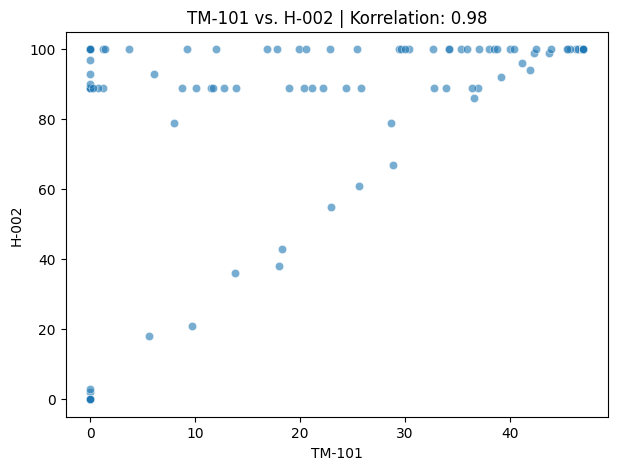

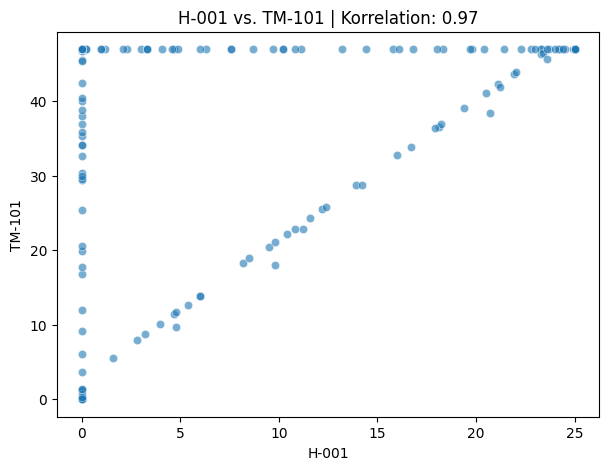

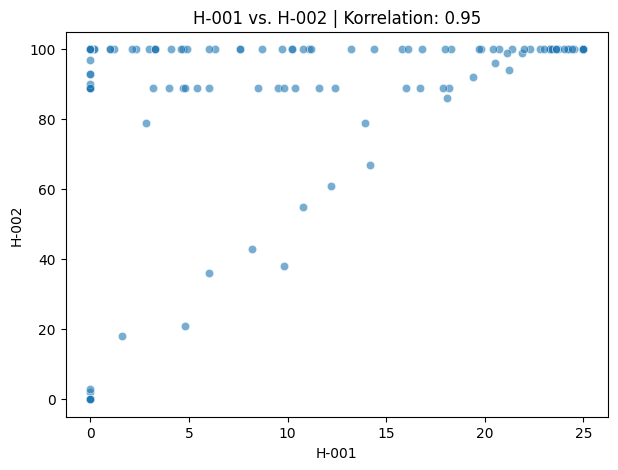

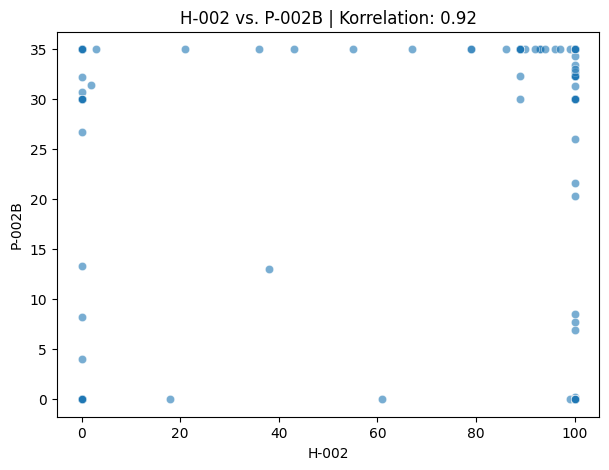

In [35]:
# ============================================================
# 8.2 Scatterplots der stärksten Korrelationen
# ============================================================

top_pairs = corr_pairs.head(4)

for _, row in top_pairs.iterrows():
    x_col = row["feature_1"]
    y_col = row["feature_2"]
    corr_value = row["correlation"]

    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=df, x=x_col, y=y_col, alpha=0.6)
    plt.title(f"{x_col} vs. {y_col} | Korrelation: {corr_value:.2f}")
    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.show()

In [36]:
# ============================================================
# 9. Zeitreihe vorbereiten
# ============================================================

df = df.copy()

# Datumsspalte in datetime umwandeln
df["Datum"] = pd.to_datetime(df["Datum"])

# Nach Datum sortieren
df = df.sort_values("Datum")

# Datum als Index setzen
df = df.set_index("Datum")

df.head()

,PARA-2024,LI-213,H-001,GM-002,GS-100,TM-101,H-002,H-005A,H-005B,P-002C,P-002B
Datum,,,,,,,,,,,
2026-03-01 00:00:00,0,2.5,25.0,35.5,100,47.0,100,0,0,0.0,35.0
2026-03-01 00:05:00,0,2.6,25.0,35.5,100,47.0,100,0,0,0.0,35.0
2026-03-01 00:10:00,0,2.4,25.0,35.4,100,47.0,100,0,0,0.0,35.0
2026-03-01 00:15:00,0,2.4,25.0,35.4,100,47.0,100,0,0,0.0,35.0
2026-03-01 00:20:00,0,2.4,25.0,35.3,100,47.0,100,0,0,0.0,35.0


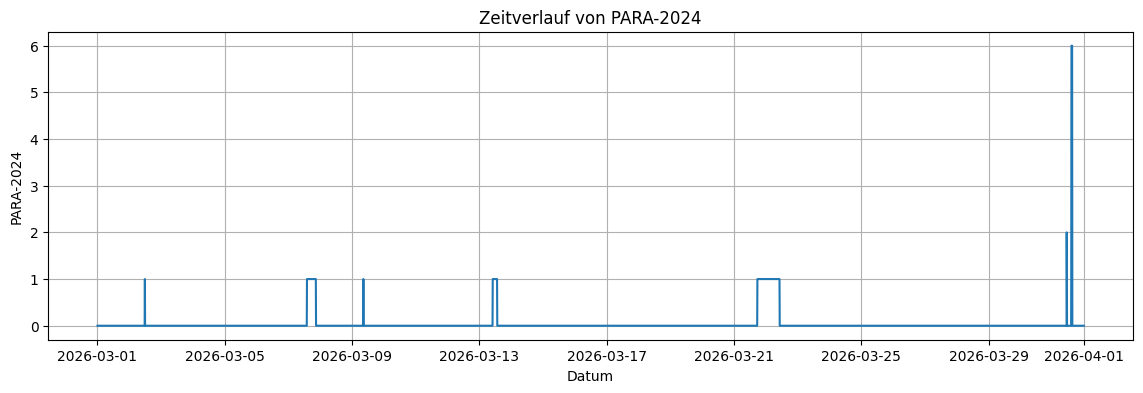

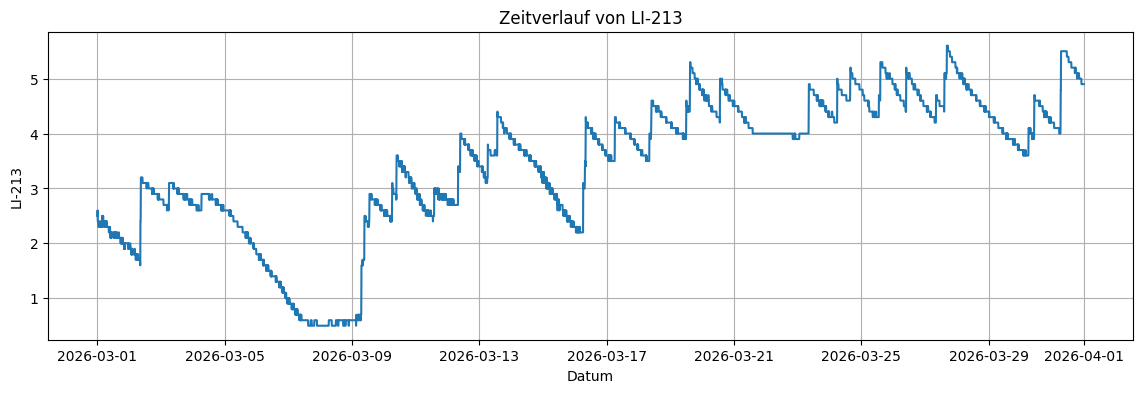

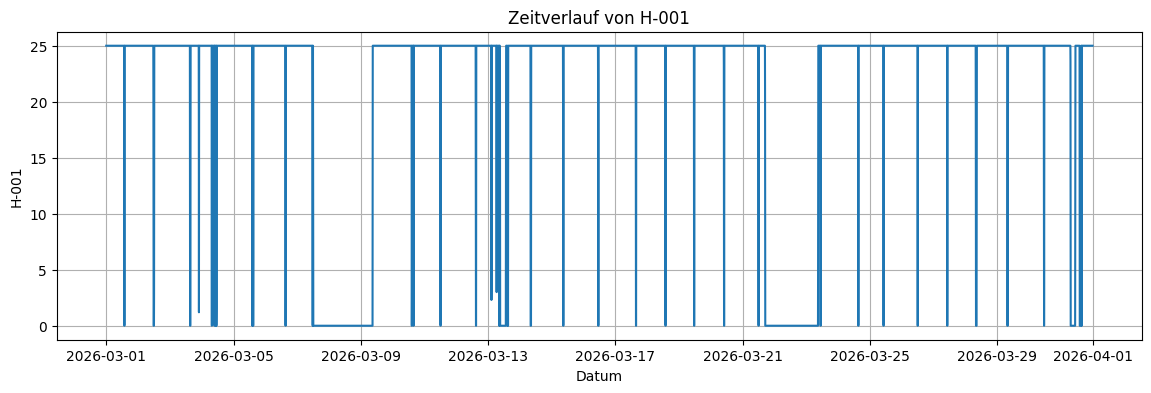

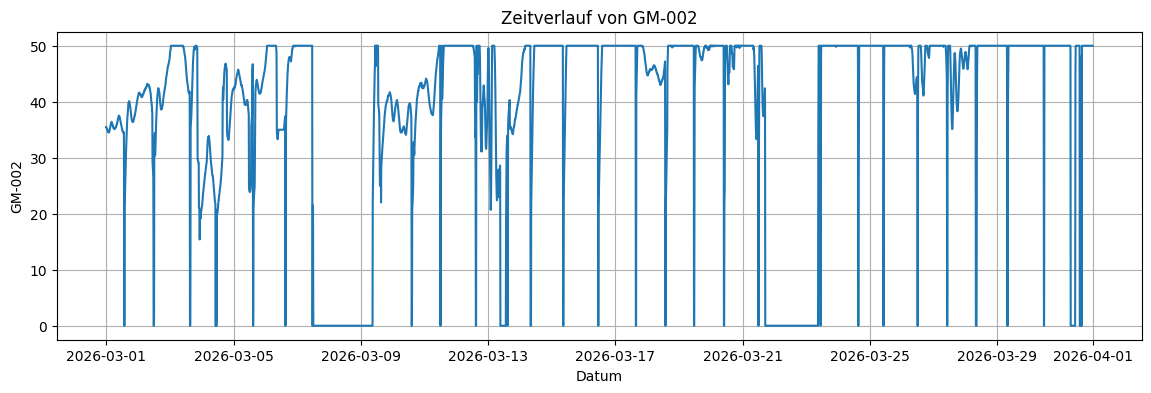

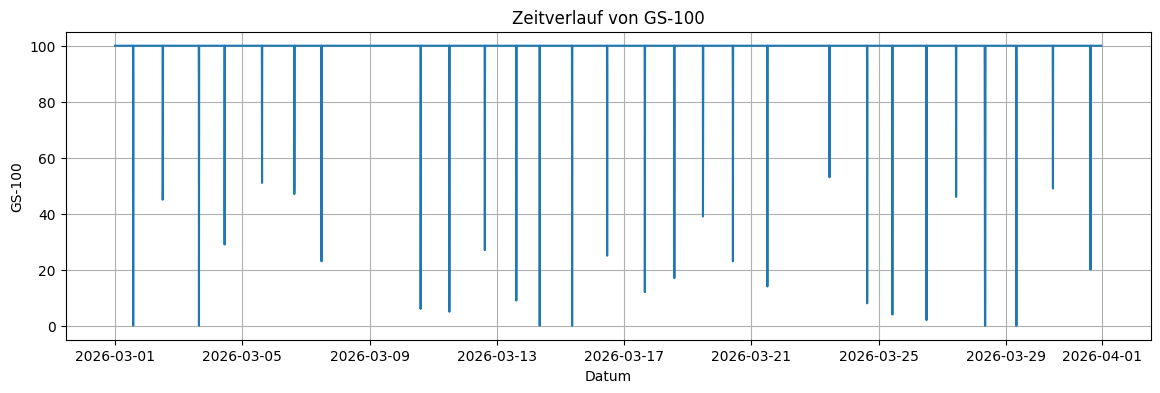

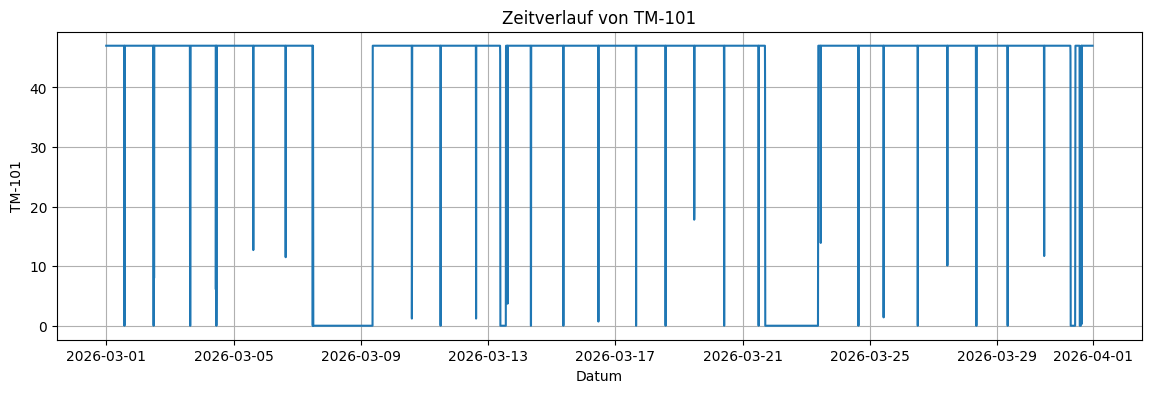

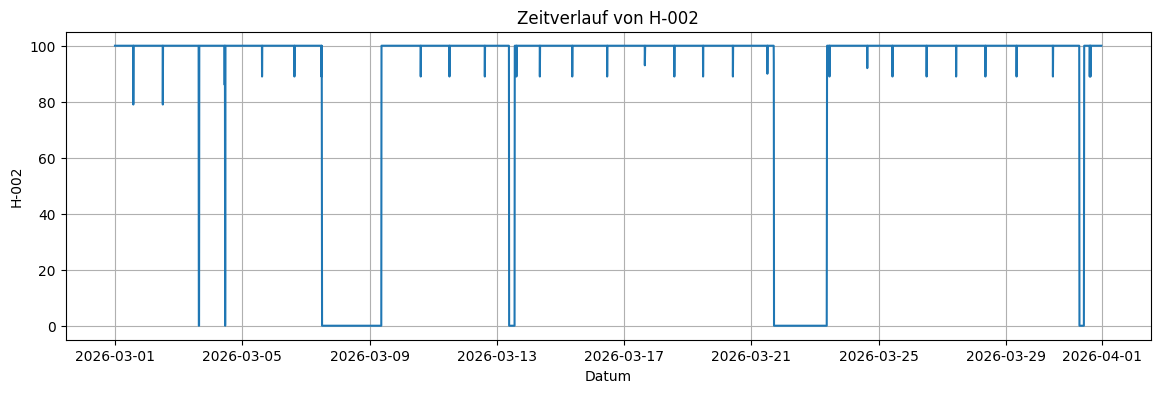

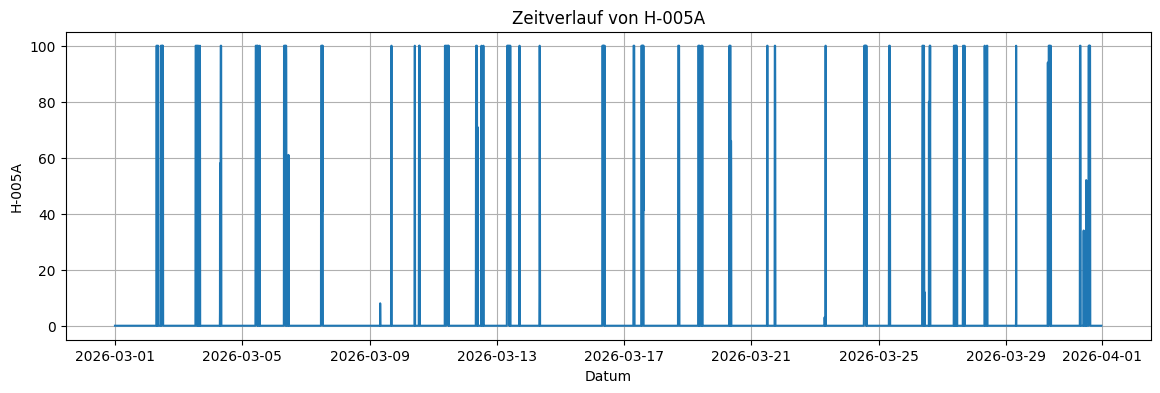

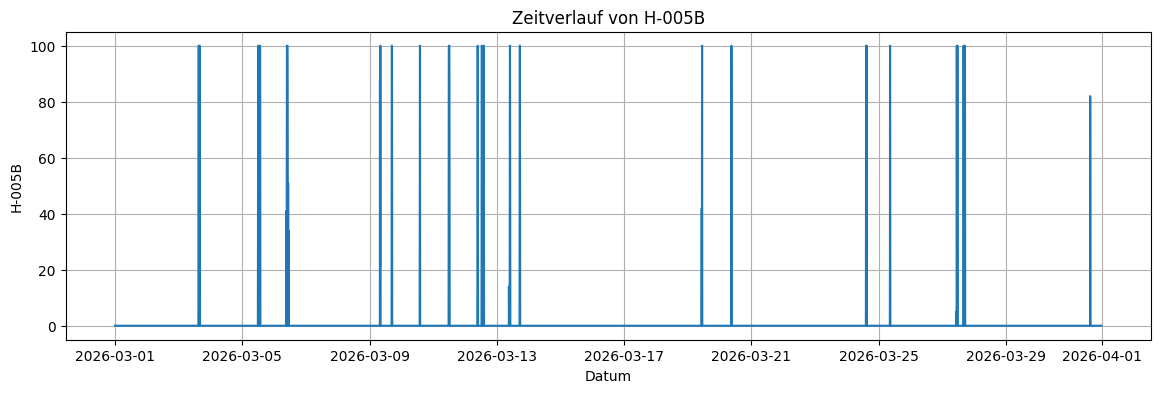

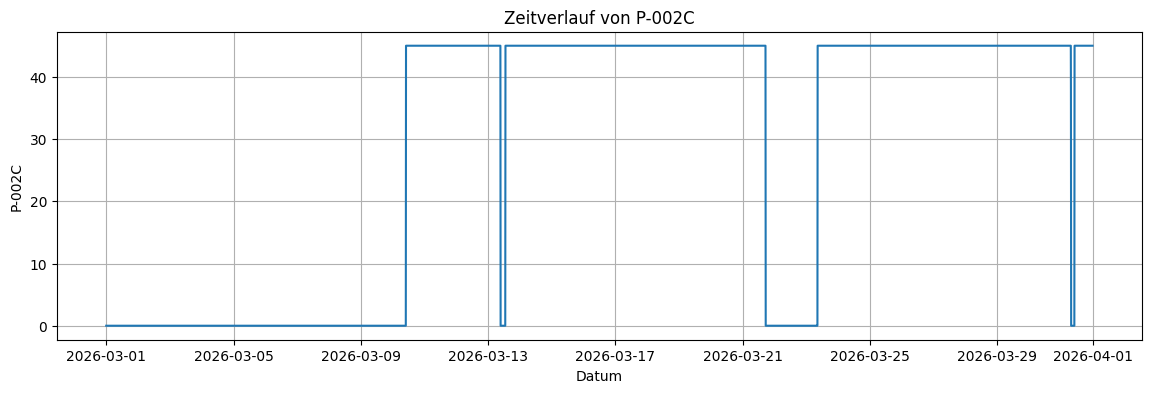

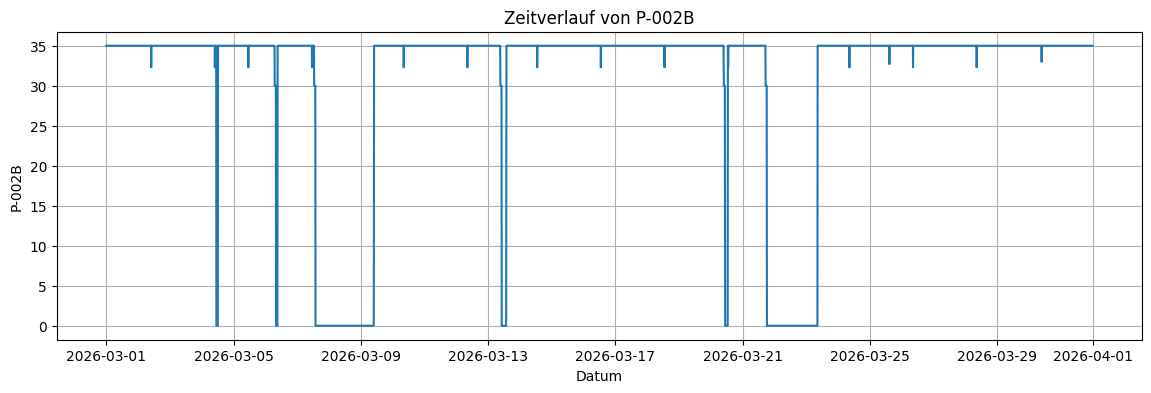

In [38]:
# ============================================================
# 9.2 Alle Parameter als einzelne Zeitreihen
# ============================================================

for col in num_cols:
    plt.figure(figsize=(14, 4))
    plt.plot(df.index, df[col])
    plt.title(f"Zeitverlauf von {col}")
    plt.xlabel("Datum")
    plt.ylabel(col)
    plt.grid(True)
    plt.show()